# Data_Download_30Coin_Universe

Daily CoinMarketCap OHLCV, market capitalization, and circulating supply for the fixed 30-coin
research universe, starting **2021-01-01** and refreshed through the latest completed UTC day.

**Run all cells in order.** By default, the notebook audits the bundled CSVs offline. Set `RUN_DOWNLOAD = True` to refresh the provider data and publish two CSV files in `OHLCV_Market_Cap_Data/`:

- `crypto_30_coin_daily_ohlcv.csv` — the unchanged shared filename used by every strategy.
- `crypto_30_coin_daily_market_cap_supply.csv` — supplemental capitalization and supply data for
  strategies that require those variables.

Market cap and supply come directly from the CoinMarketCap daily-history response. OHLCV uses the
same response except for explicitly labelled isolated gaps obtained through Yahoo's CMC-sourced
crypto history. This keeps the fields on one provider calendar while allowing strategies that need
only OHLCV to keep their existing loader and filename.

## Data contract

Each row represents one **UTC calendar date × coin**. The OHLCV file contains `date, symbol, open,
high, low, close, volume, cmc_id, ohlcv_source, retrieved_at_utc`. The supplemental file contains
`date, symbol, market_cap, circulating_supply, cmc_id, retrieved_at_utc`. Prices, volume, and
capitalization are USD-denominated provider aggregates; supply is reported coin units. Stable
CoinMarketCap IDs are used for every request so ticker collisions and symbol changes cannot silently
select another asset.

Today's incomplete UTC candle is excluded. The panel includes every requested calendar date for all
30 coins; unavailable provider observations remain empty. No forward filling, interpolation, price
adjustment, or automatic repair is applied. Nonpositive market cap or supply is retained as reported
and highlighted for downstream eligibility rules.

This is a **fixed, retrospectively selected universe**, not a historical top-30 ranking or a
survivorship-free sample. CoinMarketCap data may be revised and does not establish executable
exchange prices. Token migrations are not automatically spliced into different assets.

Dependencies: Python 3.10+, `requests`, NumPy, pandas, Matplotlib, and Jupyter.

Provider interface: CoinMarketCap's public historical-data page endpoint. It returns the same daily
OHLCV, market-cap, and supply fields displayed by the provider's historical pages. Requests are
chunked backward in time because the page endpoint returns at most 400 daily observations per call.
If that response omits an isolated OHLCV candle, the notebook requests only that missing date through
Yahoo Finance, whose listed cryptocurrency data provider is CoinMarketCap, and marks the row as a
fallback. Supplemental CMC fields remain missing rather than being inferred.


**Scope:** this notebook prepares and audits market data; it does not simulate a strategy account, so strategy Sharpe and alpha inference are not applicable here. Sharpe and HAC alpha uncertainty are reported in the six research studies and final portfolio notebook.


In [1]:
from pathlib import Path
import hashlib
import os
import platform
import tempfile
import time

import requests
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import yfinance as yf
from IPython.display import display

NOTEBOOK_NAME = "Data_Download_30Coin_Universe.ipynb"
PROJECT_ROOT = Path(".")
if not (PROJECT_ROOT / NOTEBOOK_NAME).is_file():
    raise FileNotFoundError("Run from the repository root containing this notebook.")

OUTPUT_DIR = Path("OHLCV_Market_Cap_Data")
CSV_PATH = OUTPUT_DIR / "crypto_30_coin_daily_ohlcv.csv"
SUPPLEMENTAL_CSV_PATH = OUTPUT_DIR / "crypto_30_coin_daily_market_cap_supply.csv"
RUN_DOWNLOAD = False  # Set True to refresh provider data; otherwise audit the bundled CSVs.
START_DATE = pd.Timestamp("2021-01-01")
RUN_TIME = pd.Timestamp.now(tz="UTC")
END_EXCLUSIVE = RUN_TIME.normalize().tz_localize(None)
if not RUN_DOWNLOAD:
    END_EXCLUSIVE = pd.read_csv(CSV_PATH, usecols=["date"], parse_dates=["date"])["date"].max() + pd.Timedelta(days=1)
CALENDAR = pd.date_range(START_DATE, END_EXCLUSIVE - pd.Timedelta(days=1), freq="D", name="date")
RETRIEVED_AT = RUN_TIME.isoformat()
OHLCV_FIELDS = ["open", "high", "low", "close", "volume"]
SUPPLEMENTAL_FIELDS = ["market_cap", "circulating_supply"]
ALL_FIELDS = OHLCV_FIELDS + SUPPLEMENTAL_FIELDS
MAX_ATTEMPTS = 3
REQUEST_TIMEOUT = 30
REQUEST_PAUSE = 0.15
CMC_HISTORY_URL = "https://api.coinmarketcap.com/data-api/v3.1/cryptocurrency/historical"
USD_CONVERT_ID = 2781

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "#fcfcfd",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.labelcolor": "#374151",
    "text.color": "#1f2937", "font.size": 10, "legend.frameon": False,
    "grid.color": "#cbd5e1", "grid.alpha": .3,
})
pd.set_option("display.max_rows", 40)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | requests {requests.__version__}")
print(f"Requested UTC dates: {START_DATE.date()} through {CALENDAR[-1].date()}")
print(f"Shared OHLCV CSV: {CSV_PATH.relative_to(PROJECT_ROOT).as_posix()}")
print(f"Supplemental CSV: {SUPPLEMENTAL_CSV_PATH.relative_to(PROJECT_ROOT).as_posix()}")


Python 3.13.2 | pandas 3.0.3 | requests 2.32.5
Requested UTC dates: 2021-01-01 through 2026-09-26
Shared OHLCV CSV: OHLCV_Market_Cap_Data/crypto_30_coin_daily_ohlcv.csv
Supplemental CSV: OHLCV_Market_Cap_Data/crypto_30_coin_daily_market_cap_supply.csv


## 1. Fixed coin universe

CoinMarketCap's numeric IDs are the provider keys; readable symbols remain the canonical dataset
labels. In particular, Uniswap is requested with CMC ID 7083 but remains `UNI` in both CSV files.
The universe stays exactly 30 coins even when a provider observation is unavailable.


In [2]:
SECTORS = {
    "Store of Value / Benchmark": ["BTC"],
    "Layer 1 Smart Contracts": ["ETH", "SOL", "BNB", "ADA", "AVAX", "DOT", "NEAR", "ATOM", "TRX", "ALGO", "HBAR"],
    "Payments & Legacy": ["XRP", "DOGE", "LTC", "BCH", "ETC", "XLM"],
    "DeFi Protocols": ["AAVE", "MKR", "UNI", "CRV", "INJ", "RUNE"],
    "Infrastructure, Storage & Metaverse": ["LINK", "FIL", "VET", "THETA", "SAND", "MANA"],
}
SYMBOLS = [symbol for members in SECTORS.values() for symbol in members]
CMC_IDS = {
    "AAVE": 7278, "ADA": 2010, "ALGO": 4030, "ATOM": 3794, "AVAX": 5805,
    "BCH": 1831, "BNB": 1839, "BTC": 1, "CRV": 6538, "DOGE": 74,
    "DOT": 6636, "ETC": 1321, "ETH": 1027, "FIL": 2280, "HBAR": 4642,
    "INJ": 7226, "LINK": 1975, "LTC": 2, "MANA": 1966, "MKR": 1518,
    "NEAR": 6535, "RUNE": 4157, "SAND": 6210, "SOL": 5426, "THETA": 2416,
    "TRX": 1958, "UNI": 7083, "VET": 3077, "XLM": 512, "XRP": 52,
}
YAHOO_SYMBOLS = {symbol: f"{symbol}-USD" for symbol in SYMBOLS}
YAHOO_SYMBOLS["UNI"] = "UNI7083-USD"
assert len(SYMBOLS) == len(set(SYMBOLS)) == 30
assert set(CMC_IDS) == set(SYMBOLS) and len(set(CMC_IDS.values())) == 30
display(pd.DataFrame([
    {"sector": sector, "coins": ", ".join(members)}
    for sector, members in SECTORS.items()
]))


,sector,coins
0,Store of Value / Benchmark,BTC
1,Layer 1 Smart Contracts,"ETH, SOL, BNB, ADA, AVAX, DOT, NEAR, ATOM, TRX..."
2,Payments & Legacy,"XRP, DOGE, LTC, BCH, ETC, XLM"
3,DeFi Protocols,"AAVE, MKR, UNI, CRV, INJ, RUNE"
4,"Infrastructure, Storage & Metaverse","LINK, FIL, VET, THETA, SAND, MANA"


## 2. Download and validate

Each run refreshes the full sample so provider revisions are captured. Every response is checked for
a successful provider status and the requested CMC ID. Requests have bounded retries and exponential
backoff; no coin is silently dropped or substituted.

Empty downloads, duplicate dates, infinite values, nonpositive prices, negative volume, and
inconsistent OHLC bars block publication. Isolated OHLCV gaps in the direct CMC response are filled
only from Yahoo's CMC-sourced cryptocurrency history and are explicitly labelled in `ohlcv_source`.
Supplemental gaps are never filled or inferred. Zero volume, market cap, or supply is retained exactly
as reported and flagged. Both CSV files are validated through temporary files before replacing the
published snapshots.


In [3]:
session = requests.Session()
session.headers.update({"Accept": "application/json", "User-Agent": "crypto-factor-research/1.0"})

def utc_end_timestamp(date):
    end = pd.Timestamp(date).tz_localize("UTC") + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)
    return int(end.timestamp())

def request_history_chunk(symbol, end_date):
    params = {
        "id": CMC_IDS[symbol],
        "convertId": USD_CONVERT_ID,
        "timeEnd": utc_end_timestamp(end_date),
        "interval": "1d",
    }
    errors = []
    for attempt in range(1, MAX_ATTEMPTS + 1):
        try:
            response = session.get(CMC_HISTORY_URL, params=params, timeout=REQUEST_TIMEOUT)
            response.raise_for_status()
            payload = response.json()
            status = payload.get("status", {})
            if str(status.get("error_code")) != "0":
                raise ValueError(f"CMC status: {status.get('error_message')}")
            data = payload.get("data") or {}
            if int(data.get("id", -1)) != CMC_IDS[symbol]:
                raise ValueError("Response CMC ID does not match the requested asset.")
            quotes = data.get("quotes") or []
            if not quotes:
                raise ValueError("CoinMarketCap returned no daily observations.")
            return quotes
        except Exception as exc:
            errors.append(f"Attempt {attempt}: {type(exc).__name__}: {exc}")
            if attempt < MAX_ATTEMPTS:
                time.sleep(2 ** attempt)
    raise RuntimeError(f"CMC ID {CMC_IDS[symbol]}: " + " | ".join(errors))

def normalize_history(records, symbol):
    rows = []
    for record in records:
        quote = record.get("quote") or {}
        rows.append({
            "date": pd.to_datetime(record.get("timeOpen"), utc=True, errors="raise").tz_localize(None).normalize(),
            "open": quote.get("open"), "high": quote.get("high"), "low": quote.get("low"),
            "close": quote.get("close"), "volume": quote.get("volume"),
            "market_cap": quote.get("marketCap"),
            "circulating_supply": quote.get("circulatingSupply"),
        })
    frame = pd.DataFrame(rows).set_index("date").sort_index()
    if frame.index.has_duplicates:
        duplicates = frame.index[frame.index.duplicated()].unique().strftime("%Y-%m-%d").tolist()
        raise ValueError(f"Duplicate daily timestamps: {duplicates[:5]}")
    frame = frame.loc[(frame.index >= START_DATE) & (frame.index < END_EXCLUSIVE), ALL_FIELDS]
    for field in ALL_FIELDS:
        frame[field] = pd.to_numeric(frame[field], errors="raise")
    if frame.empty or frame["close"].notna().sum() == 0:
        raise ValueError("No closing prices in the requested date range.")
    values = frame.to_numpy(dtype=float)
    if np.isinf(values).any():
        raise ValueError("Infinite values.")
    prices = frame[["open", "high", "low", "close"]]
    if (prices <= 0).any().any() or (frame["volume"] < 0).any():
        raise ValueError("Nonpositive price or negative volume.")
    if (frame[SUPPLEMENTAL_FIELDS] < 0).any().any():
        raise ValueError("Negative market cap or circulating supply.")
    complete_prices = prices.dropna()
    tolerance = 1e-8 * complete_prices.abs().max(axis=1).clip(lower=1)
    bad_high = complete_prices["high"] + tolerance < complete_prices[["open", "low", "close"]].max(axis=1)
    bad_low = complete_prices["low"] - tolerance > complete_prices[["open", "high", "close"]].min(axis=1)
    if bad_high.any() or bad_low.any():
        raise ValueError("Inconsistent OHLC price bounds.")
    frame["ohlcv_source"] = "coinmarketcap"
    return frame.reindex(CALENDAR)

def fill_isolated_ohlcv_gaps(frame, symbol):
    missing_dates = frame.index[frame[OHLCV_FIELDS].isna().any(axis=1)]
    if len(missing_dates) == 0:
        return frame
    start = missing_dates.min()
    end = missing_dates.max() + pd.Timedelta(days=1)
    raw = yf.Ticker(YAHOO_SYMBOLS[symbol]).history(
        start=start.strftime("%Y-%m-%d"), end=end.strftime("%Y-%m-%d"),
        interval="1d", auto_adjust=False, back_adjust=False, actions=False,
        repair=False, keepna=True, timeout=REQUEST_TIMEOUT,
    )
    if raw is None or raw.empty:
        raise ValueError(f"Yahoo CMC fallback returned no rows for {symbol} gaps.")
    raw = raw.rename(columns=str.lower)[OHLCV_FIELDS]
    raw.index = pd.to_datetime(raw.index, utc=True).tz_localize(None).normalize()
    for date in missing_dates:
        if date not in raw.index or raw.loc[date, OHLCV_FIELDS].isna().any():
            raise ValueError(f"No fallback OHLCV observation for {symbol} on {date.date()}.")
        frame.loc[date, OHLCV_FIELDS] = raw.loc[date, OHLCV_FIELDS].to_numpy(dtype=float)
        frame.loc[date, "ohlcv_source"] = "yahoo_finance_cmc_fallback"
    prices = frame[OHLCV_FIELDS[:4]]
    if prices.isna().any().any() or (prices <= 0).any().any() or frame["volume"].isna().any() or (frame["volume"] < 0).any():
        raise ValueError(f"OHLCV panel remains invalid after the {symbol} fallback.")
    return frame

def download_coin(symbol):
    chunks = []
    cursor = CALENDAR[-1]
    while cursor >= START_DATE:
        quotes = request_history_chunk(symbol, cursor)
        chunk = []
        for record in quotes:
            date = pd.to_datetime(record.get("timeOpen"), utc=True, errors="raise").tz_localize(None).normalize()
            if date <= cursor:
                chunk.append(record)
        if not chunk:
            raise ValueError(f"No observations at or before requested cursor {cursor.date()}.")
        chunks.extend(chunk)
        earliest = min(pd.to_datetime(r["timeOpen"], utc=True).tz_localize(None).normalize() for r in chunk)
        if earliest <= START_DATE:
            break
        cursor = earliest - pd.Timedelta(days=1)
        time.sleep(REQUEST_PAUSE)
    return fill_isolated_ohlcv_gaps(normalize_history(chunks, symbol), symbol)

if RUN_DOWNLOAD:
    downloaded, failures = {}, {}
    for position, symbol in enumerate(SYMBOLS, start=1):
        try:
            downloaded[symbol] = download_coin(symbol)
            observed = downloaded[symbol]["close"].notna().sum()
            print(f"[{position:02d}/30] {symbol:<5} {observed:,} closing observations")
        except Exception as exc:
            failures[symbol] = str(exc)
            print(f"[{position:02d}/30] {symbol:<5} FAILED: {exc}")
        time.sleep(REQUEST_PAUSE)

    if failures:
        display(pd.Series(failures, name="download_error").to_frame())
        raise RuntimeError(
            f"{len(failures)} coin downloads failed. Existing CSVs were not replaced; resolve errors and rerun."
        )
else:
    # Read the frozen input files without changing their values, timestamps, or checksums.
    cached_prices = pd.read_csv(CSV_PATH, parse_dates=["date"])
    cached_caps = pd.read_csv(SUPPLEMENTAL_CSV_PATH, parse_dates=["date"])
    assert not cached_prices.duplicated(["date", "symbol"]).any()
    assert not cached_caps.duplicated(["date", "symbol"]).any()
    cached = cached_prices.merge(cached_caps[["date", "symbol", *SUPPLEMENTAL_FIELDS]],
                                 on=["date", "symbol"], validate="one_to_one")
    assert len(cached) == len(cached_prices) == len(cached_caps)
    assert set(cached.symbol) == set(SYMBOLS)
    downloaded = {symbol: cached.loc[cached.symbol.eq(symbol)].set_index("date").sort_index()
                  .drop(columns=["symbol", "cmc_id"]).reindex(CALENDAR) for symbol in SYMBOLS}
    print("Auditing bundled inputs; provider downloads are disabled.")


Auditing bundled inputs; provider downloads are disabled.


In [4]:
audit_rows = []
ohlcv_parts, supplemental_parts = [], []
for symbol in SYMBOLS:
    frame = downloaded[symbol]
    first, last = frame["close"].first_valid_index(), frame["close"].last_valid_index()
    audit_rows.append({
        "symbol": symbol,
        "first_close": first.date(),
        "last_close": last.date(),
        "closing_observations": int(frame["close"].notna().sum()),
        "missing_ohlcv_days": int(frame[OHLCV_FIELDS].isna().any(axis=1).sum()),
        "internal_missing_close_days": int(frame.loc[first:last, "close"].isna().sum()),
        "zero_volume_days": int(frame["volume"].eq(0).sum()),
        "Yahoo CMC fallback days": int(frame["ohlcv_source"].eq("yahoo_finance_cmc_fallback").sum()),
        "missing_market_cap_days": int(frame["market_cap"].isna().sum()),
        "nonpositive_market_cap_days": int(frame["market_cap"].le(0).sum()),
        "missing_supply_days": int(frame["circulating_supply"].isna().sum()),
        "nonpositive_supply_days": int(frame["circulating_supply"].le(0).sum()),
        "days_behind_requested_end": (CALENDAR[-1] - last).days,
    })
    base = frame.reset_index()
    base.insert(1, "symbol", symbol)
    base["cmc_id"] = CMC_IDS[symbol]
    base["retrieved_at_utc"] = RETRIEVED_AT if RUN_DOWNLOAD else frame["retrieved_at_utc"].to_numpy()
    ohlcv_parts.append(base[["date", "symbol", *OHLCV_FIELDS, "cmc_id", "ohlcv_source", "retrieved_at_utc"]])
    supplemental_parts.append(base[["date", "symbol", *SUPPLEMENTAL_FIELDS, "cmc_id", "retrieved_at_utc"]])

audit = pd.DataFrame(audit_rows).set_index("symbol")
panel = pd.concat(ohlcv_parts, ignore_index=True).sort_values(["date", "symbol"]).reset_index(drop=True)
supplemental_panel = pd.concat(supplemental_parts, ignore_index=True).sort_values(["date", "symbol"]).reset_index(drop=True)
for name, frame in [("OHLCV", panel), ("supplemental", supplemental_panel)]:
    assert len(frame) == len(CALENDAR) * 30, name
    assert not frame.duplicated(["date", "symbol"]).any(), name
display(audit)
if audit["missing_ohlcv_days"].any():
    print("Data notice:", "Missing OHLCV observations are retained as empty CSV fields. Review the coverage table.")
if audit["days_behind_requested_end"].any():
    print("Data notice:", "CoinMarketCap has not supplied every coin through the requested endpoint.")
if audit["Yahoo CMC fallback days"].any():
    print("Data notice:", "Direct CMC gaps were filled from Yahoo's CMC-sourced crypto history and labelled per row.")
if audit["zero_volume_days"].any():
    print("Data notice:", "Zero reported volume is retained; volume diagnostics exclude nonpositive observations.")
if audit[["missing_market_cap_days", "nonpositive_market_cap_days", "missing_supply_days", "nonpositive_supply_days"]].any().any():
    print("Data notice:", "Missing or nonpositive supplemental observations are retained for downstream eligibility rules.")
print(f"{len(panel):,} rows | {len(CALENDAR):,} calendar dates | 30 coins | two aligned panels")


,first_close,last_close,closing_observations,missing_ohlcv_days,internal_missing_close_days,zero_volume_days,Yahoo CMC fallback days,missing_market_cap_days,nonpositive_market_cap_days,missing_supply_days,nonpositive_supply_days,days_behind_requested_end
symbol,,,,,,,,,,,,
BTC,2021-01-01,2026-09-26,2095,0,0,0,0,0,0,0,0,0
ETH,2021-01-01,2026-09-26,2095,0,0,0,0,0,0,0,0,0
SOL,2021-01-01,2026-09-26,2095,0,0,0,0,0,0,0,0,0
BNB,2021-01-01,2026-09-26,2095,0,0,0,0,0,0,0,0,0
ADA,2021-01-01,2026-09-26,2095,0,0,0,0,0,0,0,0,0
AVAX,2021-01-01,2026-09-26,2095,0,0,0,0,0,0,0,0,0
DOT,2021-01-01,2026-09-26,2095,0,0,0,0,0,0,0,0,0
NEAR,2021-01-01,2026-09-26,2095,0,0,0,0,0,1,0,1,0
ATOM,2021-01-01,2026-09-26,2095,0,0,0,0,0,0,0,0,0


Data notice: Direct CMC gaps were filled from Yahoo's CMC-sourced crypto history and labelled per row.
Data notice: Zero reported volume is retained; volume diagnostics exclude nonpositive observations.
Data notice: Missing or nonpositive supplemental observations are retained for downstream eligibility rules.
62,850 rows | 2,095 calendar dates | 30 coins | two aligned panels


In [5]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def write_verified_csv(frame, destination):
    temporary_path = None
    try:
        with tempfile.NamedTemporaryFile(
            mode="w", suffix=".csv", prefix=f".{destination.stem}_", dir=OUTPUT_DIR,
            encoding="utf-8", newline="", delete=False,
        ) as handle:
            temporary_path = Path(handle.name)
            frame.to_csv(handle, index=False, date_format="%Y-%m-%d", na_rep="")
            handle.flush()
            os.fsync(handle.fileno())
        verified = pd.read_csv(temporary_path, parse_dates=["date"])
        pd.testing.assert_frame_equal(frame, verified, check_dtype=False, check_exact=False,
                                      rtol=1e-12, atol=1e-12)
        os.replace(temporary_path, destination)
    finally:
        if temporary_path is not None and temporary_path.exists():
            temporary_path.unlink()

if RUN_DOWNLOAD:
    write_verified_csv(panel, CSV_PATH)
    write_verified_csv(supplemental_panel, SUPPLEMENTAL_CSV_PATH)
else:
    print("Bundled CSVs verified; input files were not rewritten.")

for published in [CSV_PATH, SUPPLEMENTAL_CSV_PATH]:
    print(f"Data file: {published.relative_to(PROJECT_ROOT).as_posix()}")
    print(f"Size: {published.stat().st_size / 1_000_000:.2f} MB")
    print(f"SHA-256: {hashlib.sha256(published.read_bytes()).hexdigest()}")
display(panel)
display(supplemental_panel)


Bundled CSVs verified; input files were not rewritten.
Data file: OHLCV_Market_Cap_Data/crypto_30_coin_daily_ohlcv.csv
Size: 8.40 MB
SHA-256: 9cafef5935bb06669045d8fd3060ca9cc3f8a46ff3489c73912bb0d25c6ada6f
Data file: OHLCV_Market_Cap_Data/crypto_30_coin_daily_market_cap_supply.csv
Size: 5.04 MB
SHA-256: 2efe48d13b898eb964bab00cdab4b8d5654c26d30cc89e1c8fa24caf5829ea3d


,date,symbol,open,high,low,close,volume,cmc_id,ohlcv_source,retrieved_at_utc
0,2021-01-01,AAVE,87.543306,90.349671,85.125597,90.349671,2.025158e+08,7278,coinmarketcap,2026-09-27T01:16:11.686064+00:00
1,2021-01-01,ADA,0.181382,0.184246,0.172022,0.175350,1.122218e+09,2010,coinmarketcap,2026-09-27T01:16:11.686064+00:00
2,2021-01-01,ALGO,0.334207,0.431286,0.332387,0.398129,3.418857e+08,4030,coinmarketcap,2026-09-27T01:16:11.686064+00:00
3,2021-01-01,ATOM,6.490297,6.506998,5.652401,5.868556,4.923877e+08,3794,coinmarketcap,2026-09-27T01:16:11.686064+00:00
4,2021-01-01,AVAX,3.153535,3.873537,3.054542,3.664823,8.126074e+07,5805,coinmarketcap,2026-09-27T01:16:11.686064+00:00
...,...,...,...,...,...,...,...,...,...,...
62845,2026-09-26,TRX,0.338153,0.338156,0.334055,0.334283,2.568517e+08,1958,coinmarketcap,2026-09-27T01:16:11.686064+00:00
62846,2026-09-26,UNI,9.626199,9.796016,9.422387,9.696619,6.017391e+08,7083,coinmarketcap,2026-09-27T01:16:11.686064+00:00
62847,2026-09-26,VET,0.009520,0.009823,0.009185,0.009320,2.080690e+07,3077,coinmarketcap,2026-09-27T01:16:11.686064+00:00
62848,2026-09-26,XLM,0.220229,0.222047,0.213769,0.216586,1.815742e+08,512,coinmarketcap,2026-09-27T01:16:11.686064+00:00


,date,symbol,market_cap,circulating_supply,cmc_id,retrieved_at_utc
0,2021-01-01,AAVE,1.087593e+09,1.203760e+07,7278,2026-09-27T01:16:11.686064+00:00
1,2021-01-01,ADA,5.455572e+09,3.111248e+10,2010,2026-09-27T01:16:11.686064+00:00
2,2021-01-01,ALGO,4.755064e+08,1.194352e+09,4030,2026-09-27T01:16:11.686064+00:00
3,2021-01-01,ATOM,1.221517e+09,2.081462e+08,3794,2026-09-27T01:16:11.686064+00:00
4,2021-01-01,AVAX,2.819607e+08,7.693706e+07,5805,2026-09-27T01:16:11.686064+00:00
...,...,...,...,...,...,...
62845,2026-09-26,TRX,3.174679e+10,9.496982e+10,1958,2026-09-27T01:16:11.686064+00:00
62846,2026-09-26,UNI,6.016773e+09,6.205024e+08,7083,2026-09-27T01:16:11.686064+00:00
62847,2026-09-26,VET,8.014219e+08,8.598504e+10,3077,2026-09-27T01:16:11.686064+00:00
62848,2026-09-26,XLM,7.574056e+09,3.497018e+10,512,2026-09-27T01:16:11.686064+00:00


## 3. Load once for downstream strategies

Every strategy continues to load `crypto_30_coin_daily_ohlcv.csv` using the established filename and
columns. Only strategies that require capitalization or reported supply load the supplemental CSV.
Both files have the same date × symbol rows, CMC IDs, and retrieval timestamp.

Daily returns below use adjacent calendar days only. A missing price breaks the return calculation;
missing days are never bridged or filled. All plots describe the full available sample and make no
strategy-selection claims.


In [6]:
market_data = pd.read_csv(CSV_PATH, parse_dates=["date"])
supplemental_data = pd.read_csv(SUPPLEMENTAL_CSV_PATH, parse_dates=["date"])
if not market_data[["date", "symbol", "cmc_id"]].equals(
    supplemental_data[["date", "symbol", "cmc_id"]]
):
    raise ValueError("OHLCV and supplemental CSV keys are not exactly aligned.")
prices = market_data.pivot(index="date", columns="symbol", values="close").reindex(columns=SYMBOLS)
volume = market_data.pivot(index="date", columns="symbol", values="volume").reindex(columns=SYMBOLS)
market_cap = supplemental_data.pivot(index="date", columns="symbol", values="market_cap").reindex(columns=SYMBOLS)
circulating_supply = supplemental_data.pivot(
    index="date", columns="symbol", values="circulating_supply"
).reindex(columns=SYMBOLS)
simple_returns = prices.pct_change(fill_method=None)
log_returns = np.log(prices / prices.shift(1))

def polish_axis(ax):
    ax.grid(axis="y", linewidth=.6)
    ax.set_axisbelow(True)

def date_axis(ax):
    locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    polish_axis(ax)

def finish(fig, title):
    fig.suptitle(title, fontsize=15, fontweight="bold")
    fig.tight_layout(rect=[0, 0, 1, .95])
    plt.show()
    plt.close(fig)

DISPLAY_ASSETS = ["BTC", "ETH", "SOL", "XRP"]
COLORS = {"BTC": "#ce8c2c", "ETH": "#6673b4", "SOL": "#2c927f", "XRP": "#668092"}


## 4. Market context

Normalized closes use each coin's first available price. Aggregate volume requires valid positive observations for all 30 coins; an incomplete universe total is left missing. The 30-day average requires a complete 30-calendar-day window.


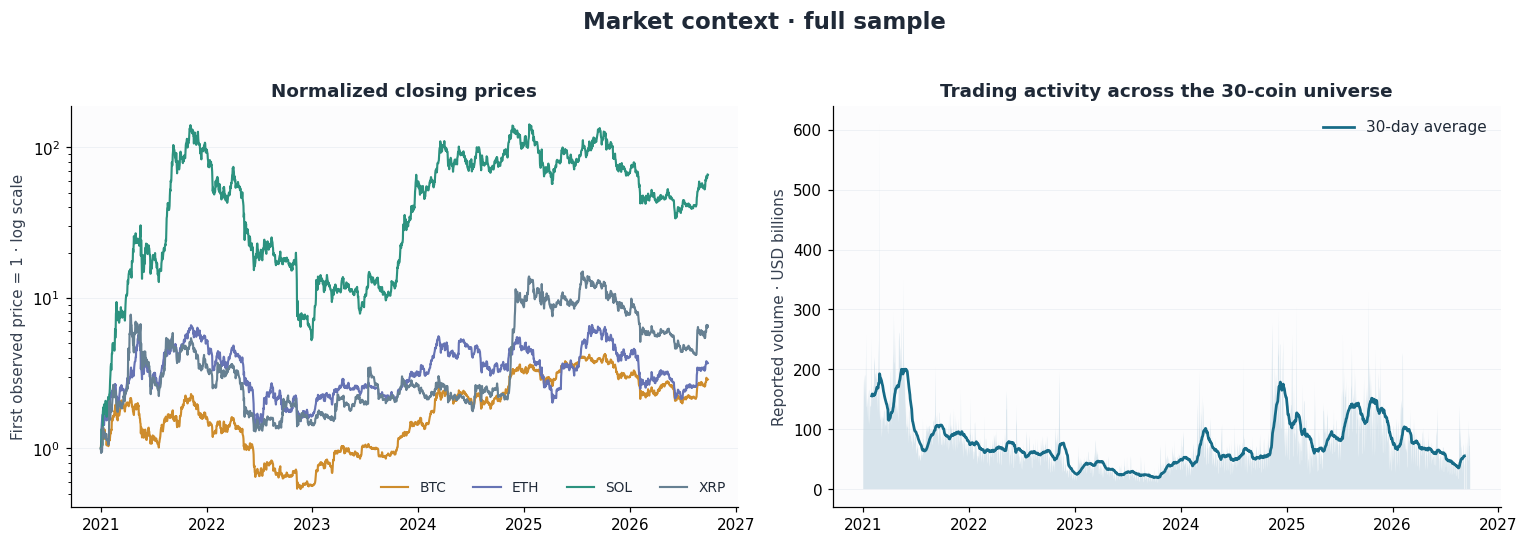

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for symbol in DISPLAY_ASSETS:
    series = prices[symbol]
    axes[0].plot(series.index, series / series.dropna().iloc[0],
                 label=symbol, color=COLORS[symbol], lw=1.4)
axes[0].set_yscale("log")
axes[0].set_title("Normalized closing prices")
axes[0].set_ylabel("First observed price = 1 · log scale")
axes[0].legend(ncol=4, fontsize=9)
activity = volume.where(volume > 0).sum(axis=1, min_count=30) / 1e9
axes[1].fill_between(activity.index, activity, color="#bcd2df", alpha=.55, linewidth=0)
axes[1].plot(activity.index, activity.rolling(30, min_periods=30).mean(),
             color="#176b87", lw=1.8, label="30-day average")
axes[1].set_title("Trading activity across the 30-coin universe")
axes[1].set_ylabel("Reported volume · USD billions")
axes[1].legend()
for ax in axes:
    date_axis(ax)
finish(fig, "Market context · full sample")


## 5. Daily return distributions and autocorrelation

These follow the Zarattini reference's input diagnostics using simple returns. Distribution views show the central 99% while sample moments use all valid observations. Autocorrelation is evaluated at exact calendar lags; the shaded range describes dispersion across coins, not a significance interval.


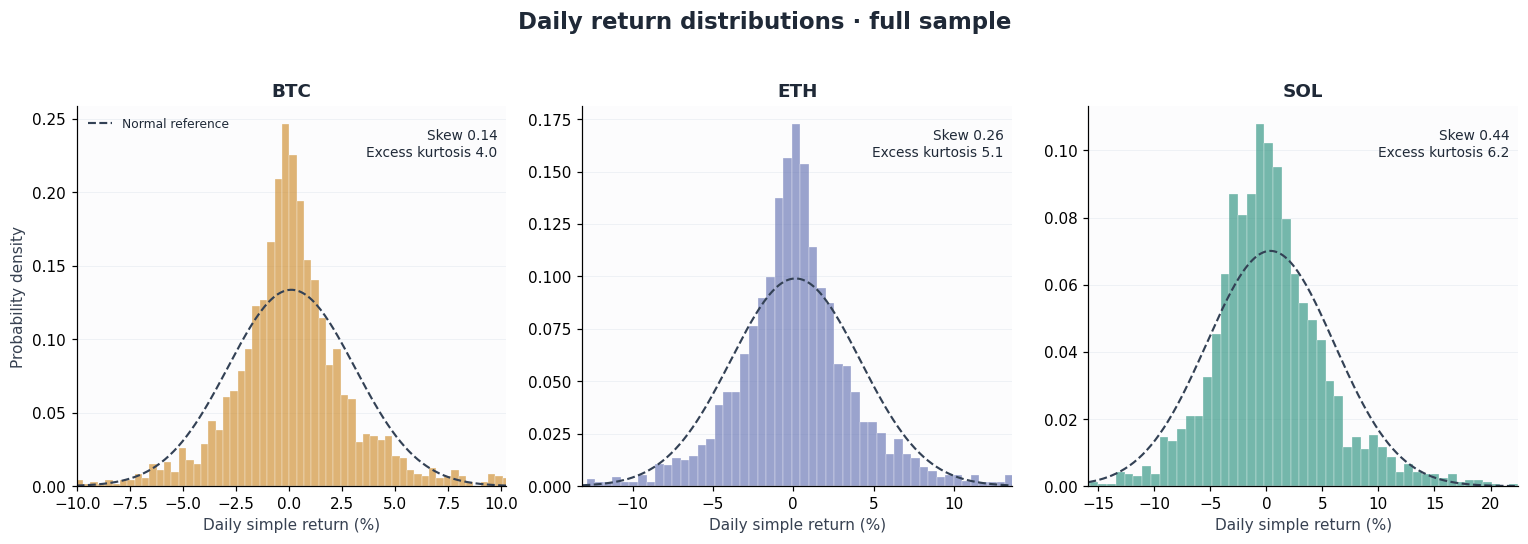

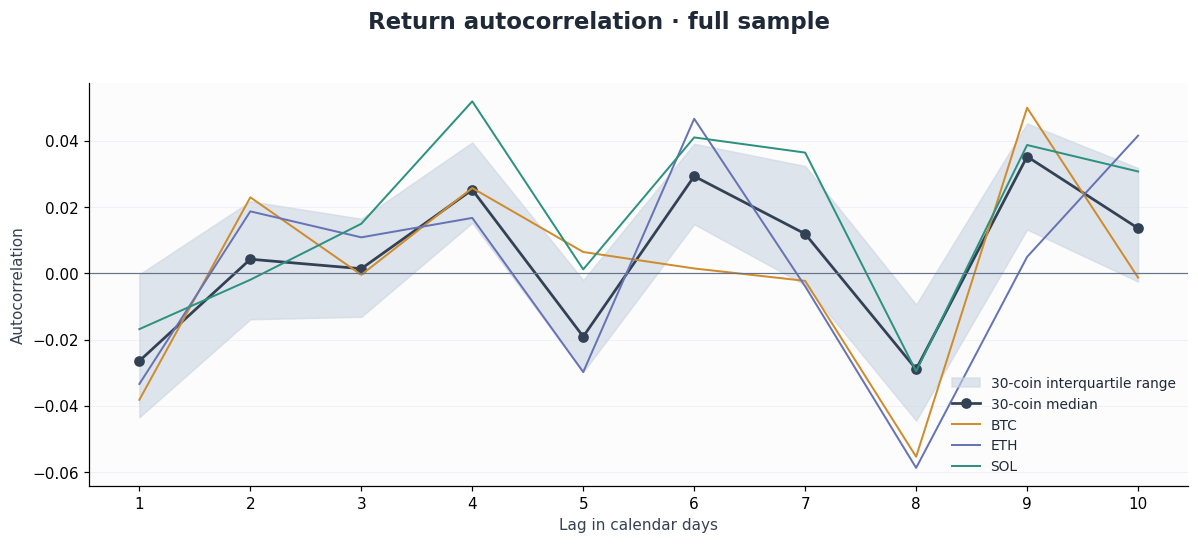

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
for ax, symbol in zip(axes, DISPLAY_ASSETS[:3]):
    sample = simple_returns[symbol].dropna() * 100
    lo, hi = sample.quantile([.005, .995])
    grid = np.linspace(lo, hi, 200)
    mu, sd = sample.mean(), sample.std(ddof=1)
    ax.hist(sample, bins=100, density=True, color=COLORS[symbol],
            alpha=.65, edgecolor="white", linewidth=.3)
    if sd > 0:
        ax.plot(grid, np.exp(-.5 * ((grid - mu) / sd) ** 2) / (sd * np.sqrt(2 * np.pi)),
                color="#334155", ls="--", lw=1.4, label="Normal reference")
    ax.set_xlim(lo, hi)
    ax.set_title(symbol)
    ax.set_xlabel("Daily simple return (%)")
    ax.text(.98, .94, f"Skew {sample.skew():.2f}\nExcess kurtosis {sample.kurt():.1f}",
            transform=ax.transAxes, ha="right", va="top", fontsize=9)
    polish_axis(ax)
axes[0].set_ylabel("Probability density")
axes[0].legend(fontsize=8)
finish(fig, "Daily return distributions · full sample")

lags = np.arange(1, 11)
acf = pd.DataFrame({lag: simple_returns.apply(lambda s: s.autocorr(lag=lag)) for lag in lags})
fig, ax = plt.subplots(figsize=(11, 5))
ax.fill_between(lags, acf.quantile(.25), acf.quantile(.75),
                color="#cbd5e1", alpha=.6, label="30-coin interquartile range")
ax.plot(lags, acf.median(), color="#334155", marker="o", lw=1.8, label="30-coin median")
for symbol in DISPLAY_ASSETS[:3]:
    ax.plot(lags, acf.loc[symbol], color=COLORS[symbol], lw=1.3, label=symbol)
ax.axhline(0, color="#64748b", lw=.8)
ax.set(xlabel="Lag in calendar days", ylabel="Autocorrelation", xticks=lags)
ax.legend(fontsize=9)
polish_axis(ax)
finish(fig, "Return autocorrelation · full sample")


## 6. Annotated correlation matrix

Pearson correlations of **daily log returns**, matching the statistical-arbitrage reference. The upper triangle and diagonal are masked; the scale is fixed at −1 to +1. Each pair uses overlapping valid daily returns with a minimum of 30 observations. The overlap range is shown so differing coverage remains visible.


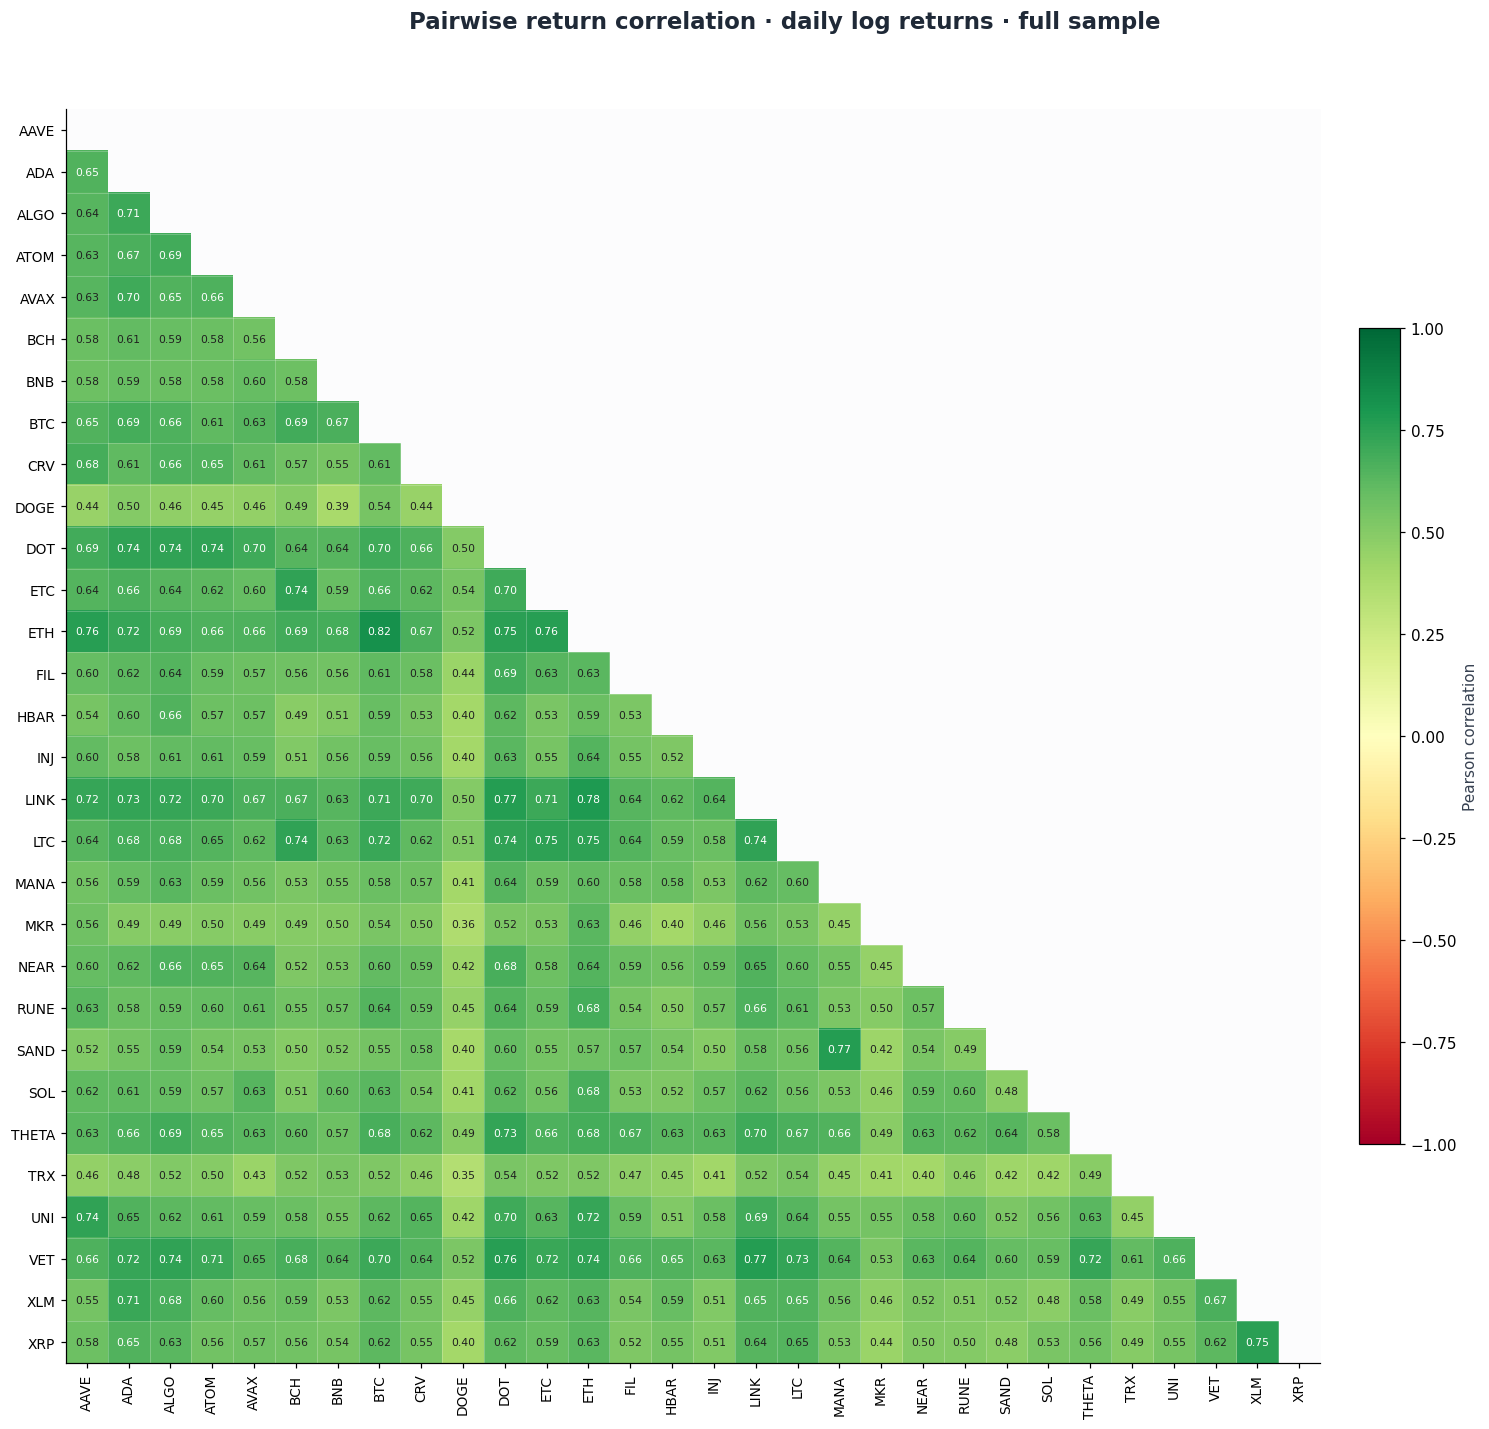

Average pairwise correlation: 0.590
Overlapping daily returns per pair: 2,094–2,094
Shared OHLCV input: OHLCV_Market_Cap_Data/crypto_30_coin_daily_ohlcv.csv
Supplemental market-cap and supply input: OHLCV_Market_Cap_Data/crypto_30_coin_daily_market_cap_supply.csv


In [9]:
ordered_returns = log_returns.reindex(columns=sorted(SYMBOLS))
correlation = ordered_returns.corr(min_periods=30)
valid = ordered_returns.notna().astype("int64")
overlap = valid.T.dot(valid)
mask = np.triu(np.ones(correlation.shape, dtype=bool))
masked = np.ma.array(correlation.to_numpy(), mask=mask | correlation.isna().to_numpy())
cmap = plt.get_cmap("RdYlGn").copy()
cmap.set_bad("#fcfcfd")
fig, ax = plt.subplots(figsize=(15, 13))
im = ax.imshow(masked, cmap=cmap, vmin=-1, vmax=1)
labels = correlation.columns.tolist()
ax.set_xticks(range(30), labels, rotation=90, fontsize=9)
ax.set_yticks(range(30), labels, fontsize=9)
ax.set_xticks(np.arange(-.5, 30, 1), minor=True)
ax.set_yticks(np.arange(-.5, 30, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=.5)
ax.tick_params(which="minor", bottom=False, left=False)
for row in range(30):
    for col in range(row):
        value = correlation.iloc[row, col]
        if pd.notna(value):
            ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if abs(value) > .65 else "#202020")
fig.colorbar(im, ax=ax, shrink=.65, pad=.025, label="Pearson correlation")
finish(fig, "Pairwise return correlation · daily log returns · full sample")
lower = np.tril_indices(30, k=-1)
print(f"Average pairwise correlation: {np.nanmean(correlation.to_numpy()[lower]):.3f}")
counts = overlap.to_numpy()[lower]
print(f"Overlapping daily returns per pair: {counts.min():,}–{counts.max():,}")
print(f"Shared OHLCV input: {CSV_PATH.relative_to(PROJECT_ROOT).as_posix()}")
print(f"Supplemental market-cap and supply input: {SUPPLEMENTAL_CSV_PATH.relative_to(PROJECT_ROOT).as_posix()}")
